# Hydro, Wind, Solar, Biomass and Geothermal Energy in the Southern U.S. Region
## Review 1: Time-Series Analysis (Trend, Seasonality, Stationarity, ACF / PACF)

This project analyses how electricity generation from **hydro, wind, solar, biomass and geothermal** sources changes over time in the
**Southern U.S. Census region**. It covers 17 jurisdictions: Delaware, D.C., Florida, Georgia, Maryland, North Carolina, South Carolina, Virginia,
West Virginia, Alabama, Kentucky, Mississippi, Tennessee, Arkansas, Louisiana, Oklahoma and Texas.

**Wind** is included alongside hydro, solar, biomass and geothermal, because it is the South's largest renewable source.

The analysis focuses on:
* Trend
* Seasonality
* Stationarity
* Autocorrelation
* Partial autocorrelation

Each resource is analysed **separately**, because each one depends on a different natural driver (rainfall, sunlight, fuel supply).

## 1. Research Problem / Question

**Research Question**

How do hydro, wind, solar, biomass and geothermal electricity generation vary over time in the Southern U.S. region, and what specific
trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

**Objective**

To study the temporal behaviour of each renewable resource in the South by examining its trend, seasonality, stationarity,
autocorrelation and partial autocorrelation. Together these determine which forecasting models are suitable in Review 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

## 2. Dataset Understanding

The dataset is the **U.S. Energy Information Administration (EIA)** monthly net electricity generation by source, for every U.S. state
from January 2001 onwards.

| Variable | Description |
|---|---|
| month | First day of the month of the observation |
| census_region | U.S. Census region (Northeast, Midwest, South, West) |
| census_division | U.S. Census division (9 divisions) |
| hydro, wind, solar, biomass, geothermal | Net generation from each source, in **thousand MWh (= GWh)** |
| total_renewable | Sum of the five renewable sources (GWh) |
| total_generation | Net generation from all sources, renewable and non-renewable (GWh) |
| renewable_share_pct | total_renewable / total_generation × 100 |

The observations are recorded at a **monthly** frequency.

In [2]:
# Path to the dataset (on Colab: upload the CSV and change this path)
DATA_PATH = "../data/usa_state_renewable_monthly_2001_2026.csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (15657, 11)


,month,census_region,census_division,hydro,wind,solar,biomass,geothermal,total_renewable,total_generation,renewable_share_pct
0,2001-01-01,West,Pacific,104.549,0.087,0.000,0.000,0.000,104.636,590.145,17.730
1,2001-02-01,West,Pacific,90.111,0.074,0.000,0.000,0.000,90.185,546.167,16.510
2,2001-03-01,West,Pacific,99.843,0.081,0.000,0.000,0.000,99.924,587.115,17.020
3,2001-04-01,West,Pacific,84.615,0.071,0.000,0.000,0.000,84.686,488.698,17.330
4,2001-05-01,West,Pacific,85.130,0.069,0.000,0.000,0.000,85.199,484.687,17.580


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15657 entries, 0 to 15656
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                15657 non-null  datetime64[us]
 1   census_region        15657 non-null  str           
 2   census_division      15657 non-null  str           
 3   hydro                15657 non-null  float64       
 4   wind                 15657 non-null  float64       
 5   solar                15657 non-null  float64       
 6   biomass              15657 non-null  float64       
 7   geothermal           15657 non-null  float64       
 8   total_renewable      15657 non-null  float64       
 9   total_generation     15657 non-null  float64       
 10  renewable_share_pct  15642 non-null  float64       
dtypes: datetime64[us](1), float64(8), str(2)
memory usage: 1.3 MB


In [4]:
print("Census regions :", df["census_region"].unique())
print("Census divisions:", df["census_division"].nunique())
print("\nTime range:")
print("Start:", df["month"].min().date())
print("End  :", df["month"].max().date())
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Census regions : <StringArray>
['West', 'South', 'Northeast', 'Midwest']
Length: 4, dtype: str
Census divisions: 9

Time range:
Start: 2001-01-01
End  : 2026-07-01

Missing values in each column:
month                   0
census_region           0
census_division         0
hydro                   0
wind                    0
solar                   0
biomass                 0
geothermal              0
total_renewable         0
total_generation        0
renewable_share_pct    15
dtype: int64

Duplicate rows: 0


### Selecting the Southern region

For this study, only rows with `census_region == "South"` are used. Each month has one row per Southern state, so the rows are
**added together** to give one monthly total per resource for the whole region.

In [5]:
region_df = df[df["census_region"] == "South"].copy()

print("Southern rows:", region_df.shape)
print("Divisions in the South:", region_df["census_division"].unique())
print("Rows (states) per month:", region_df.groupby("month").size().unique())

region = (
    region_df
    .groupby("month")[["hydro", "solar", "biomass", "geothermal", "wind"]]
    .sum()
)
print("\nMonthly regional series:", region.shape)
region.head()

Southern rows: (5219, 11)
Divisions in the South: <StringArray>
['East South Central', 'West South Central', 'South Atlantic']
Length: 3, dtype: str
Rows (states) per month: [17]

Monthly regional series: (307, 5)


,hydro,solar,biomass,geothermal,wind
month,,,,,
2001-01-01,2711.884,0.000,2120.928,0.000,83.931
2001-02-01,3356.024,0.000,1824.703,0.000,141.647
2001-03-01,4438.626,0.000,1853.074,0.000,87.631
2001-04-01,3037.771,0.000,1928.004,0.000,115.487
2001-05-01,2033.178,0.000,1802.518,0.000,103.312


In [6]:
region.describe()

,hydro,solar,biomass,geothermal,wind
count,307.000,307.000,307.000,307.000,307.000
mean,3726.459,2004.067,2294.069,0.000,5779.474
std,1141.541,3621.849,243.419,0.000,5198.765
min,1296.180,-0.003,1637.675,0.000,55.825
25%,2802.652,0.068,2120.439,0.000,878.517
50%,3582.688,84.100,2270.026,0.000,4074.036
75%,4492.564,2246.216,2455.516,0.000,10037.591
max,7391.592,19264.384,2907.240,0.000,20212.961


In [7]:
time_difference = region.index.to_series().diff()
print("Most common time intervals between observations:")
print(time_difference.value_counts().head())

full_range = pd.date_range(region.index.min(), region.index.max(), freq="MS")
print("\nMissing months:", len(full_range.difference(region.index)))

Most common time intervals between observations:
month
31 days    178
30 days    102
28 days     20
29 days      6
Name: count, dtype: int64

Missing months: 0


In [8]:
# How many months is each resource exactly zero?
print("Months with zero generation:")
print((region == 0).sum())
print("\nTotal geothermal generation in the South, 2001-2026:", region["geothermal"].sum(), "GWh")

Months with zero generation:
hydro           0
solar          22
biomass         0
geothermal    307
wind            0
dtype: int64

Total geothermal generation in the South, 2001-2026: 0.0 GWh


**Geothermal: no data to analyse**

Geothermal generation is **0 GWh in all 307 months** (Jan 2001 – Jul 2026), in every Southern state. The South has no utility-scale
geothermal power plants, so there is no trend, seasonality or dependence to study.
Geothermal is therefore reported here and **excluded from the time-series modelling**. Its forecast is simply 0 GWh.

In [9]:
# When does solar become a measurable series?
print(region["solar"].loc["2008-01-01":"2011-06-01"].round(1).to_string())

month
2008-01-01    0.100
2008-02-01    0.100
2008-03-01    0.100
2008-04-01    0.100
2008-05-01    0.100
2008-06-01    0.100
2008-07-01    0.100
2008-08-01    0.100
2008-09-01    0.100
2008-10-01    0.100
2008-11-01    0.100
2008-12-01    1.900
2009-01-01    0.100
2009-02-01    0.300
2009-03-01    0.500
2009-04-01    0.600
2009-05-01    0.700
2009-06-01    0.600
2009-07-01    4.600
2009-08-01    4.600
2009-09-01    4.500
2009-10-01    4.300
2009-11-01    3.500
2009-12-01    2.600
2010-01-01    4.000
2010-02-01    3.500
2010-03-01    5.300
2010-04-01    9.500
2010-05-01   10.000
2010-06-01   10.100
2010-07-01    8.800
2010-08-01    8.800
2010-09-01    9.300
2010-10-01    9.200
2010-11-01   13.000
2010-12-01   10.100
2011-01-01   12.200
2011-02-01   14.800
2011-03-01   25.200
2011-04-01   18.200
2011-05-01   19.400
2011-06-01   12.500


**Choosing the start of the solar series**

Southern solar output was essentially zero until 2008 (0.1 GWh/month or less). It reached only a few GWh/month in 2009 and stays at
3.5 GWh/month or more from **January 2010** onwards. The 22 months with exactly zero output all fall before 2009.
Earlier values are too small to carry any pattern and make a log transform impossible. Solar is therefore analysed from **Jan 2010 (199 monthly observations)**.

## 3. Data Preparation

* The index is converted to a monthly datetime index with frequency `MS` (month start).
* **Geothermal is removed from the modelling**, because it is identically zero.
* **Solar** is analysed from January 2010 onwards.
* Hydro, wind and biomass use the full period, Jan 2001 – Jul 2026.

In [10]:
region = region.asfreq("MS")

RESOURCES = ["hydro", "wind", "solar", "biomass"]
SOLAR_START = "2010-01-01"

series = {
    "hydro":   region["hydro"],
    "wind":    region["wind"],
    "solar":   region["solar"].loc[SOLAR_START:],
    "biomass": region["biomass"],
}

for r in RESOURCES:
    print(f"{r:8s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}  ->  {len(series[r])} monthly observations")

hydro   : Jan 2001 - Jul 2026  ->  307 monthly observations
wind    : Jan 2001 - Jul 2026  ->  307 monthly observations
solar   : Jan 2010 - Jul 2026  ->  199 monthly observations
biomass : Jan 2001 - Jul 2026  ->  307 monthly observations


## 4. Time-Series Visualization

The plots below show how generation from each resource changes over time in the Southern region.

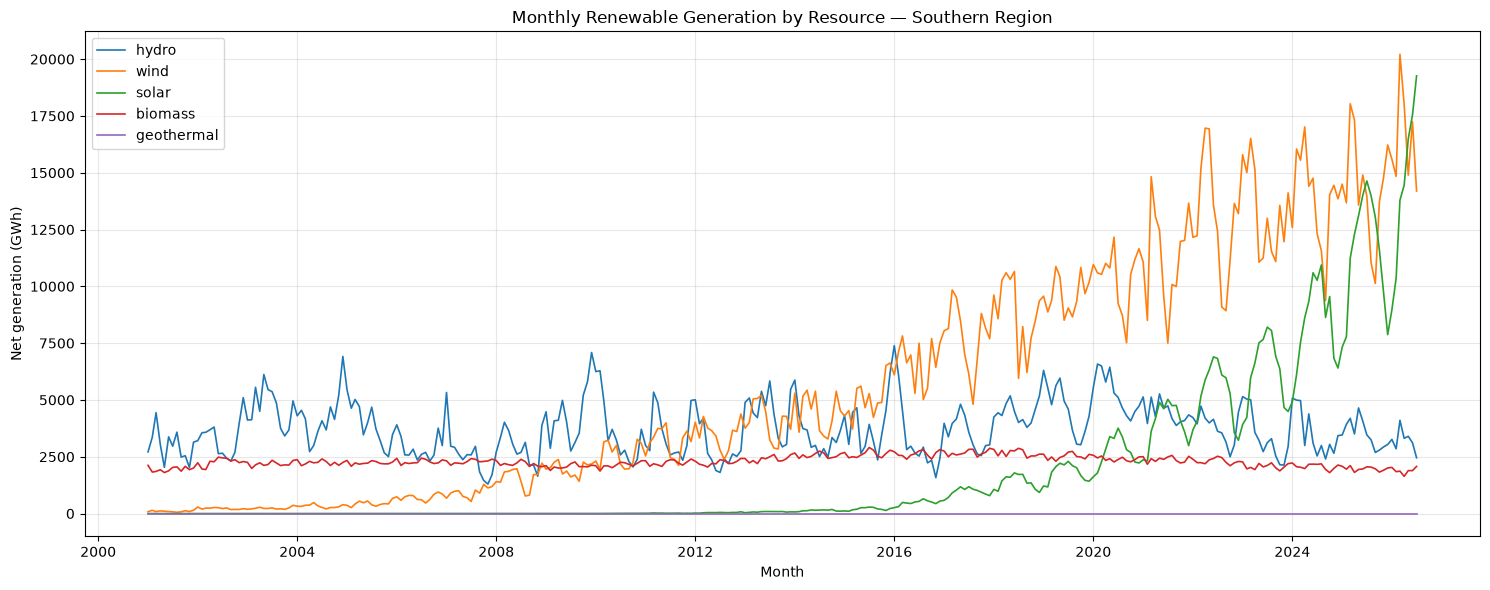

In [11]:
plt.figure(figsize=(15, 6))
for col in ["hydro", "wind", "solar", "biomass", "geothermal"]:
    plt.plot(region.index, region[col], linewidth=1.2, label=col)
plt.xlabel("Month")
plt.ylabel("Net generation (GWh)")
plt.title("Monthly Renewable Generation by Resource — Southern Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

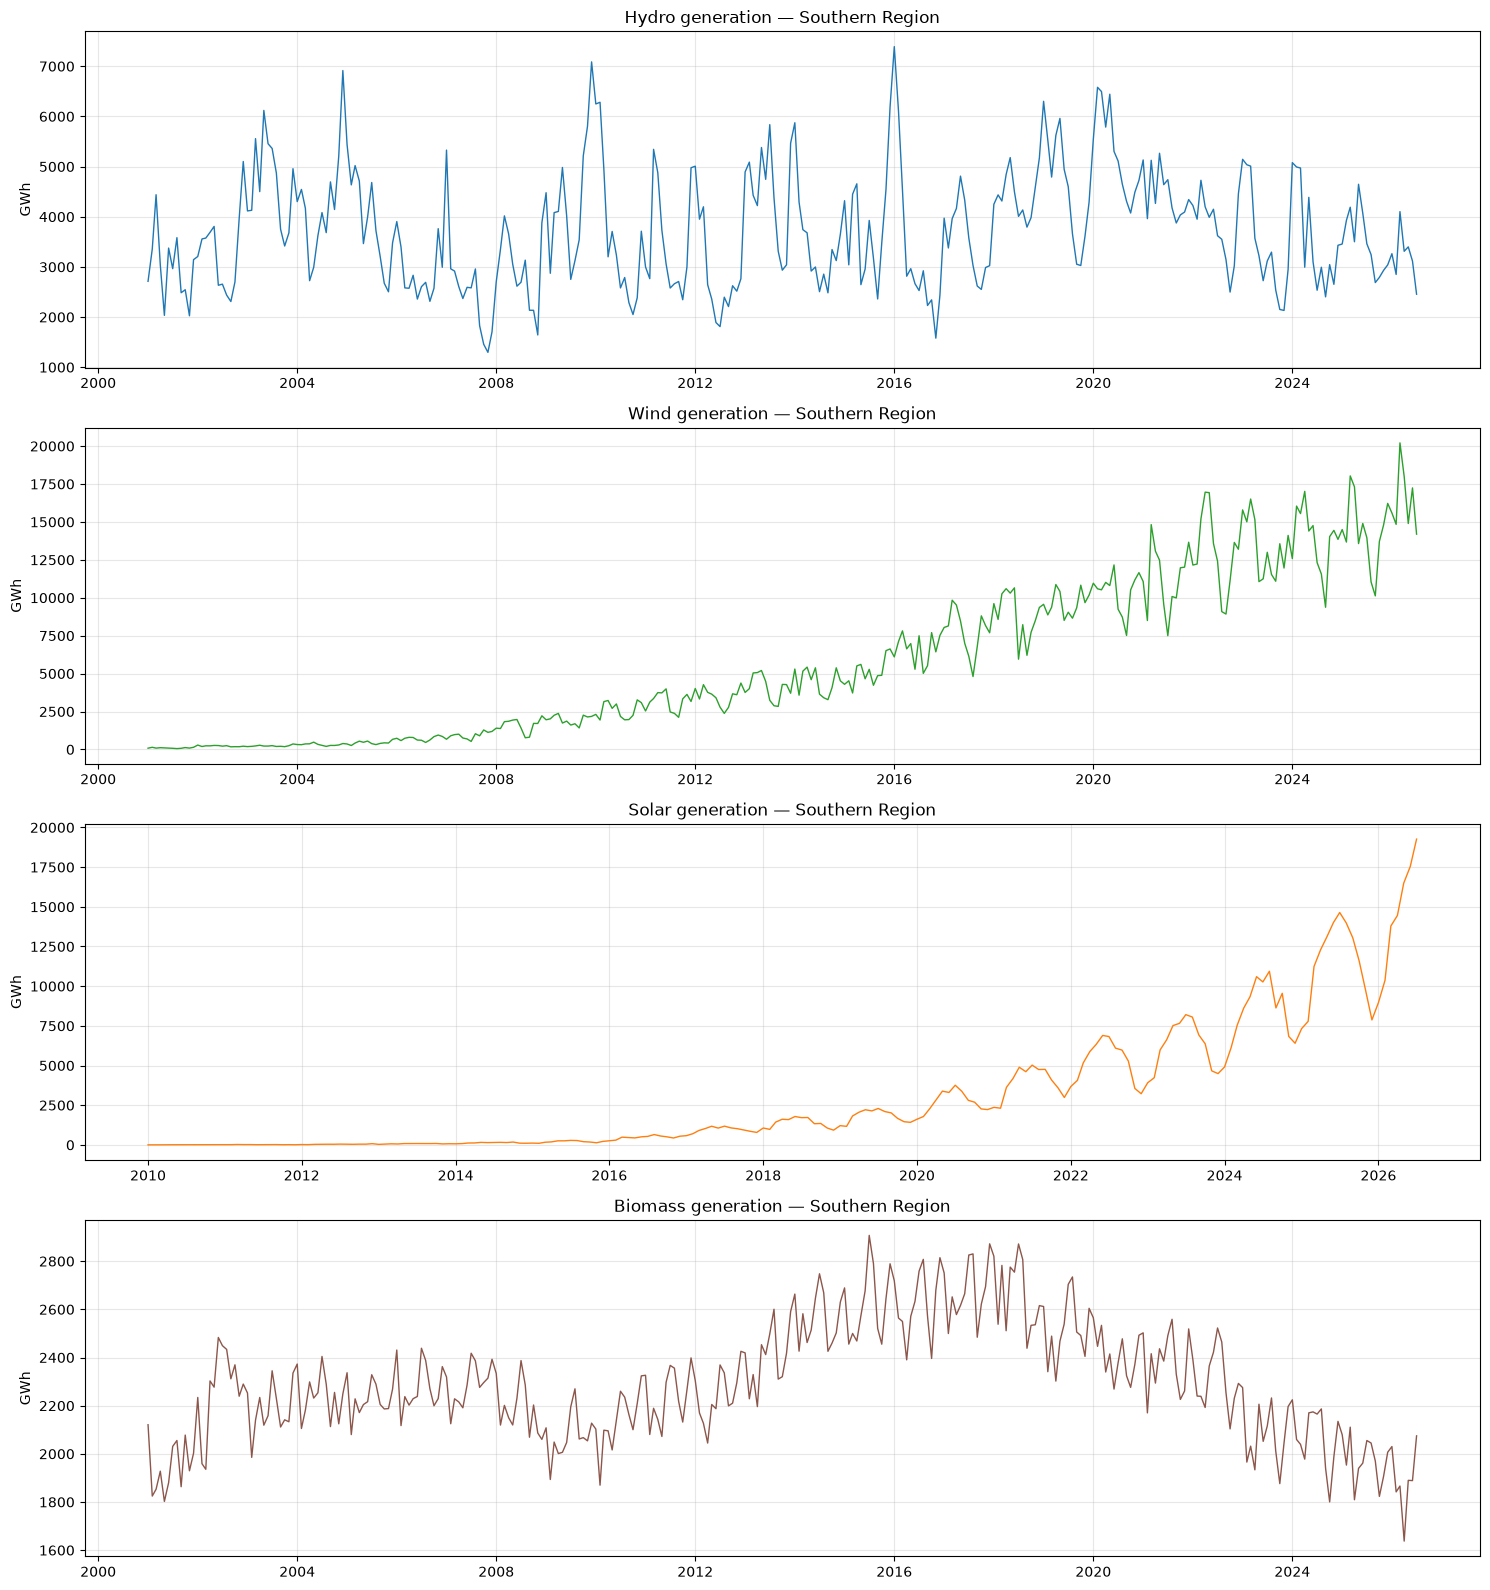

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(15, 16))
colors = {"hydro": "tab:blue", "wind": "tab:green", "solar": "tab:orange", "biomass": "tab:brown"}
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].index, series[r].values, color=colors[r], linewidth=1)
    ax.set_title(f"{r.capitalize()} generation — Southern Region")
    ax.set_ylabel("GWh")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Initial visual observations**

1. **Hydro** has no clear long-term direction. It moves between roughly 1,300 and 7,400 GWh per month, with large spikes in wet periods
   (2003, 2009–10, early 2016, 2020) and deep lows in dry years (2007–08, 2016–17). Within each year it rises in winter and spring and falls in late summer and autumn.
2. **Wind** grows steadily from about 100 GWh/month (2001) to about 9,000–20,000 GWh/month in recent years (record 20,213 GWh in Mar 2026), so it is now the South's **largest** renewable.
   It has a regular spring peak and late-summer dip, and the swings get larger as the level rises.
3. **Solar** grows explosively. It was almost invisible before 2016 and reached a record of about 19,300 GWh in Jul 2026, with a summer peak and winter dip whose size grows with the level.
4. **Biomass** is the most stable resource, at about 1,600–2,900 GWh. It rose to a plateau around 2014–2018 and has declined since.
5. **Geothermal** is a flat line at zero.

## 5. Trend Analysis

### 12-month rolling mean
A 12-month rolling mean removes the seasonal cycle and leaves the long-term movement.

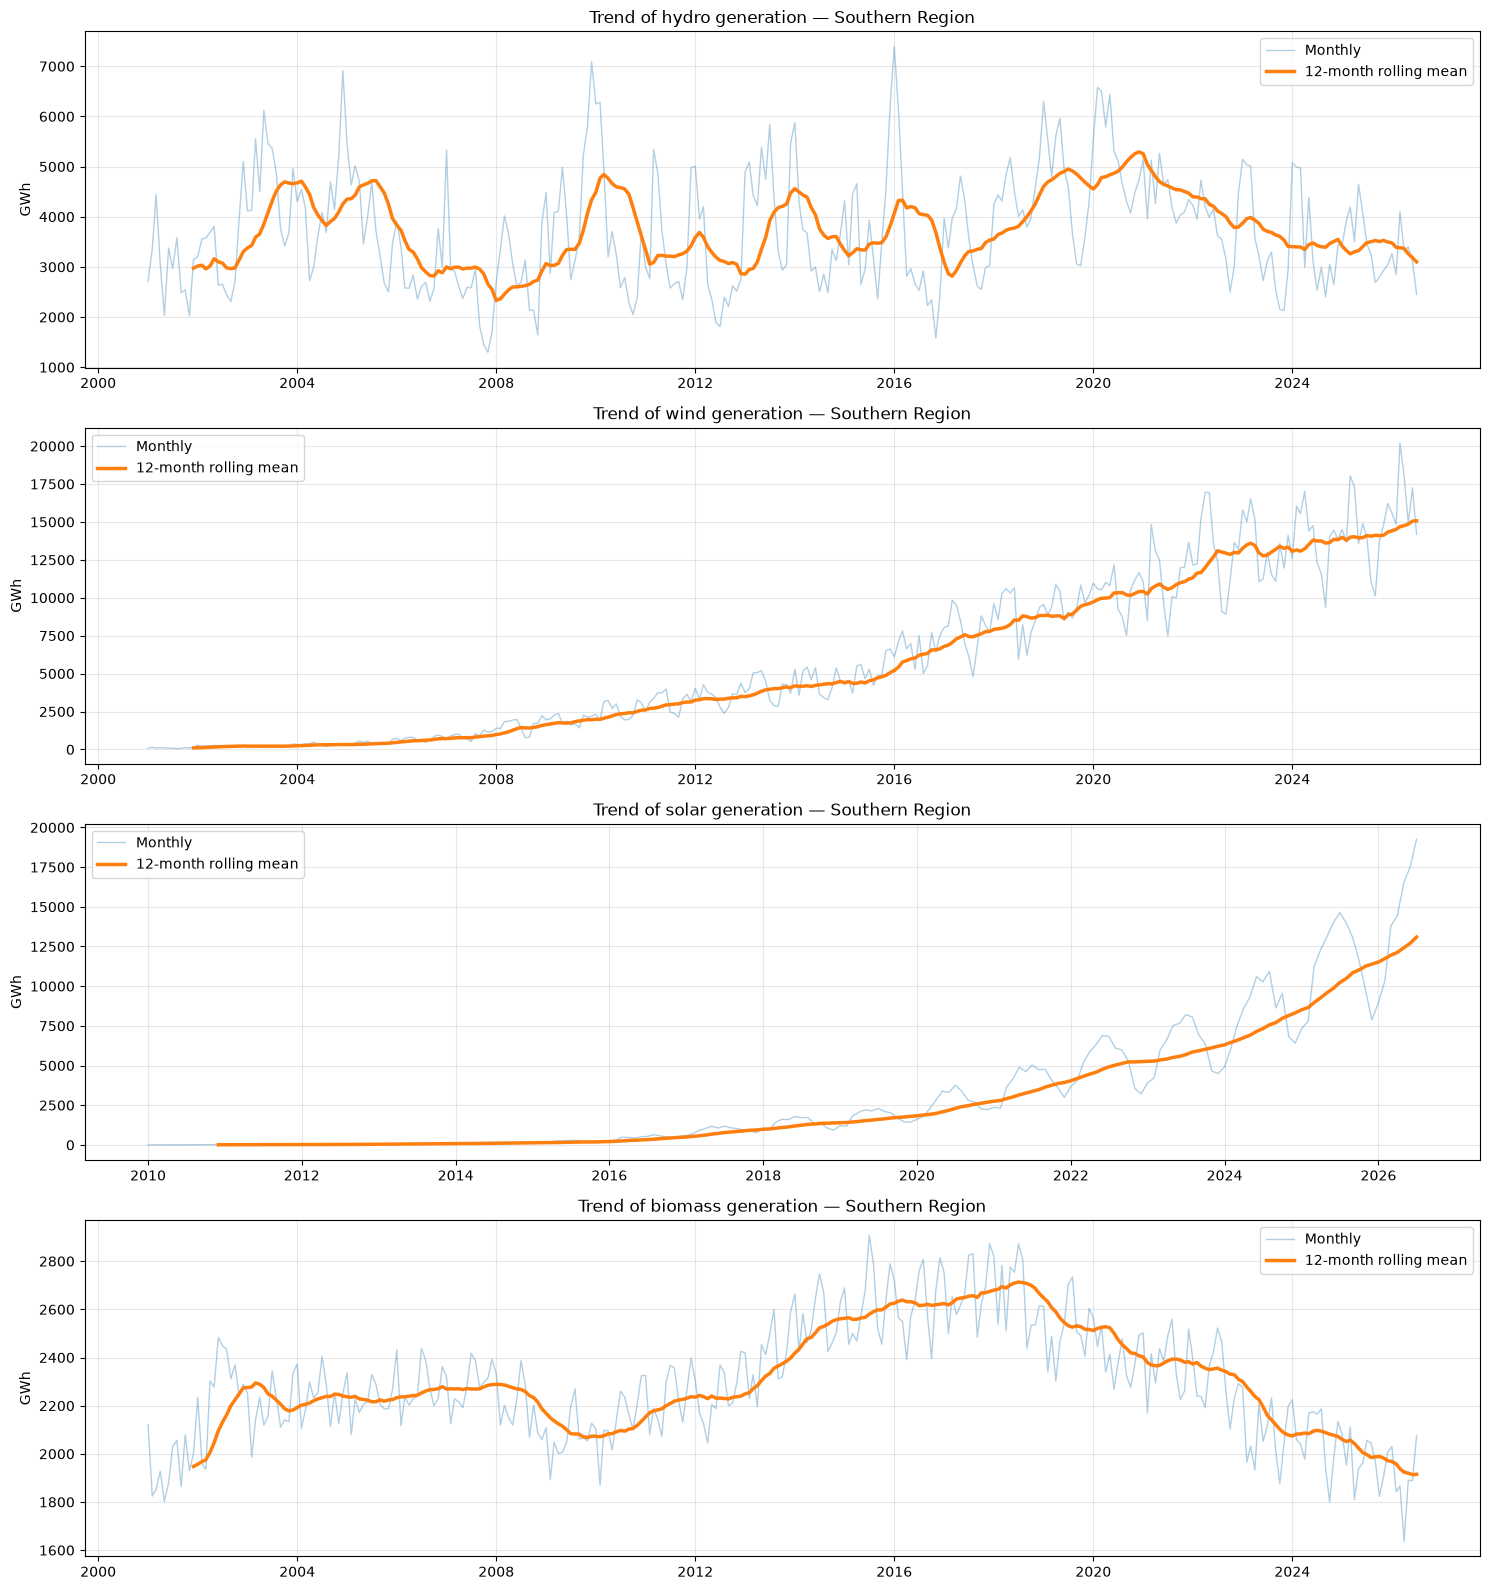

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(15, 16))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    ax.plot(s.index, s, alpha=0.35, linewidth=1, label="Monthly")
    ax.plot(s.index, s.rolling(12).mean(), linewidth=2.5, label="12-month rolling mean")
    ax.set_title(f"Trend of {r} generation — Southern Region")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Annual totals and growth
Only complete calendar years are used (2026 is partial).

In [14]:
annual = pd.DataFrame({r: series[r].resample("YS").sum() for r in RESOURCES})
annual.index = annual.index.year
annual = annual.loc[:2025]
annual.loc[annual.index < 2010, "solar"] = np.nan

print("Annual generation (GWh):")
print(annual.round(0).to_string())

Annual generation (GWh):
          hydro       wind      solar   biomass
month                                          
2001  35699.000   1188.000        NaN 23369.000
2002  39638.000   2696.000        NaN 27285.000
2003  55912.000   2798.000        NaN 26186.000
2004  51083.000   3875.000        NaN 26879.000
2005  47540.000   5242.000        NaN 26704.000
2006  34588.000   8611.000        NaN 27344.000
2007  30604.000  11073.000        NaN 27449.000
2008  35016.000  19025.000        NaN 26248.000
2009  52060.000  23518.000        NaN 24881.000
2010  43428.000  31048.000    102.000 25616.000
2011  41046.000  37585.000    185.000 26845.000
2012  34368.000  42031.000    502.000 26874.000
2013  53723.000  48796.000    863.000 28777.000
2014  41469.000  53773.000   1554.000 30728.000
2015  45736.000  60726.000   2384.000 31472.000
2016  40518.000  79627.000   5697.000 31456.000
2017  42404.000  93423.000  11319.000 32091.000
2018  53196.000 105968.000  16602.000 31985.000
2019  55387.000

In [15]:
trend_rows = []
for r in RESOURCES:
    a = annual[r].dropna()
    slope, intercept = np.polyfit(a.index, a.values, 1)          # linear trend in GWh per year
    first, last = a.index.min(), a.index.max()
    cagr = (a.loc[last] / a.loc[first]) ** (1 / (last - first)) - 1
    trend_rows.append({
        "resource": r,
        "years": f"{first}-{last}",
        "first_year_GWh": a.loc[first],
        "last_year_GWh": a.loc[last],
        "linear_slope_GWh_per_year": slope,
        "CAGR_%": cagr * 100,
        "correlation_with_time": np.corrcoef(a.index, a.values)[0, 1],
    })
trend_summary = pd.DataFrame(trend_rows).set_index("resource")
trend_summary

,years,first_year_GWh,last_year_GWh,linear_slope_GWh_per_year,CAGR_%,correlation_with_time
resource,,,,,,
hydro,2001-2025,35698.892,41948.563,282.529,0.674,0.254
wind,2001-2025,1187.510,171870.696,7826.493,23.034,0.972
solar,2010-2025,101.694,136638.036,7704.704,61.641,0.884
biomass,2001-2025,23369.181,23662.322,78.843,0.052,0.228


**Trend interpretation**

| Resource | Long-term behaviour |
|---|---|
| Hydro | **No meaningful trend.** The slope is +283 GWh/yr, but the correlation with time is only 0.25 and the compound growth rate 0.67%/yr. Annual output varies from 30,604 GWh (2007) to 63,509 GWh (2020), driven by **wet and dry years**. |
| Wind | **Strong upward trend that is slowing down.** Output rose from 1,188 GWh (2001) to 171,871 GWh (2025), about 23%/yr (r = 0.97). Annual growth fell from 31% (2016) to only about **3–4%** in 2023–2025, so wind is **maturing**. |
| Solar | **Strong, accelerating upward trend.** Output rose from 102 GWh (2010) to 136,638 GWh (2025), about 62%/yr, and 2025 was 37% above 2024. The trend is exponential. |
| Biomass | **Rise and decline.** Output rose from 23,369 GWh (2001) to a peak of 32,091 GWh (2017), then fell back to 23,662 GWh (2025). A straight-line trend is misleading here. |

**Key finding:** the four resources follow four different trends:
* flat (hydro);
* growth that is slowing (wind);
* exponential growth (solar);
* a rise followed by a decline (biomass).

### Does the variability grow with the level?
If the seasonal swings get larger as the level rises, the seasonality is **multiplicative**, and a log transform (or a multiplicative model) is needed.

In [16]:
for r in RESOURCES:
    s = series[r]
    roll_mean = s.rolling(12).mean()
    roll_std = s.rolling(12).std()
    corr = roll_mean.corr(roll_std)
    print(f"{r:8s}: correlation between 12-month rolling mean and rolling std = {corr:.3f}")

hydro   : correlation between 12-month rolling mean and rolling std = 0.205
wind    : correlation between 12-month rolling mean and rolling std = 0.953
solar   : correlation between 12-month rolling mean and rolling std = 0.976
biomass : correlation between 12-month rolling mean and rolling std = 0.314


**Additive or multiplicative?**

* **Solar** (correlation between rolling mean and rolling std = 0.976) and **wind** (0.953): seasonal swings grow with the level, so both are **multiplicative**. They are log-transformed and use multiplicative decomposition.
* **Hydro** (0.205) and **biomass** (0.314): variability does not depend on the level, so both are **additive**.

## 6. Seasonality Analysis

### Seasonal plot: one line per year

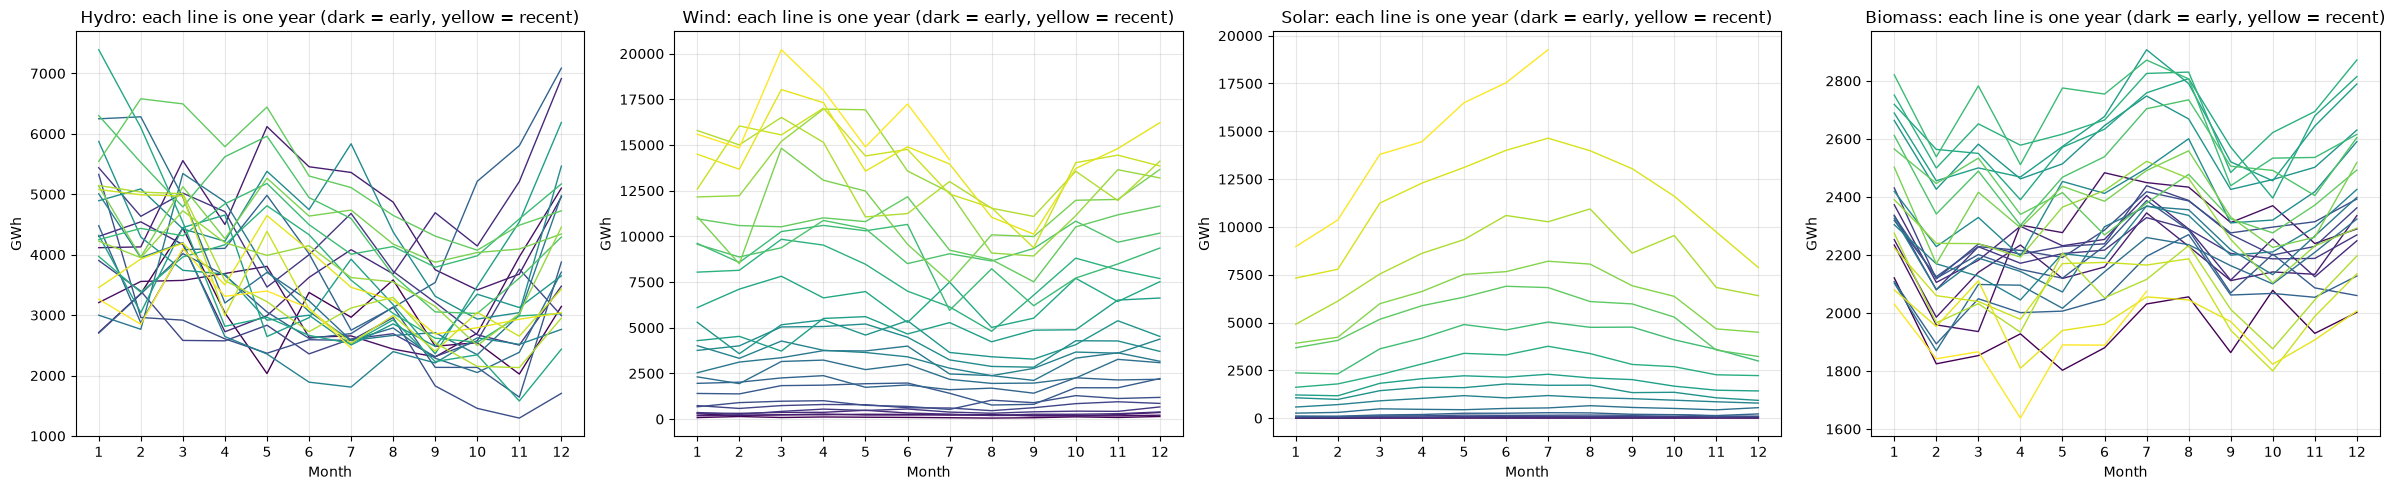

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    for year in sorted(set(s.index.year)):
        part = s[s.index.year == year]
        ax.plot(part.index.month, part.values, linewidth=1,
                color=plt.cm.viridis((year - s.index.year.min()) / (s.index.year.max() - s.index.year.min())))
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
    ax.set_ylabel("GWh")
    ax.set_title(f"{r.capitalize()}: each line is one year (dark = early, yellow = recent)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Average monthly profile
To remove the trend first, each month is divided by its own 12-month centred moving average. A value of 1.10 means 10% above the trend level.

       hydro  wind  solar  biomass
month                             
1      1.247 1.072  0.763    1.040
2      1.127 1.002  0.792    0.942
3      1.195 1.191  1.119    0.986
4      1.044 1.225  1.143    0.958
5      1.069 1.126  1.244    0.991
6      0.947 1.046  1.203    1.009
7      0.919 0.865  1.232    1.059
8      0.908 0.770  1.157    1.055
9      0.771 0.762  1.033    0.972
10     0.790 0.965  0.936    0.966
11     0.845 0.983  0.757    0.986
12     1.094 1.052  0.725    1.038


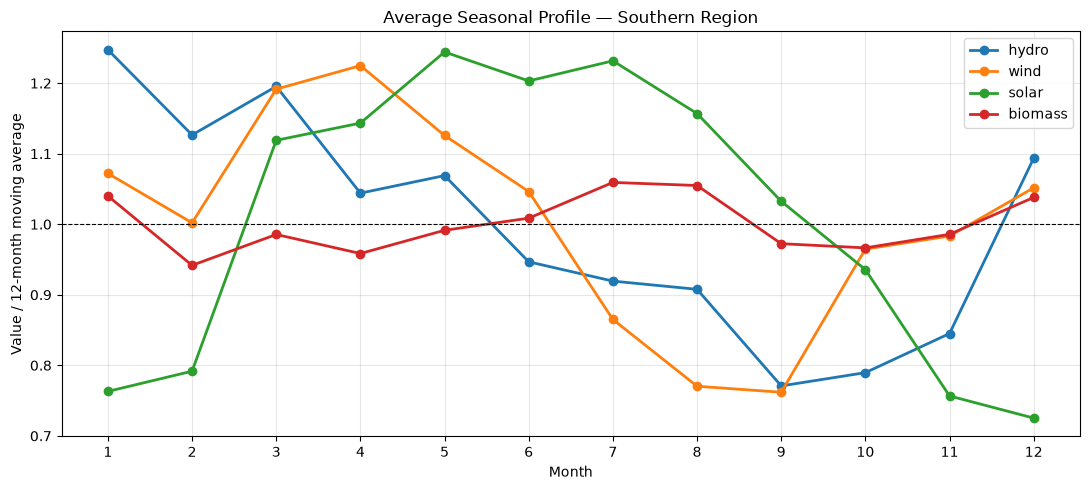

hydro   : peak month =  1 (+24.7%), trough month =  9 (-22.9%)
wind    : peak month =  4 (+22.5%), trough month =  9 (-23.8%)
solar   : peak month =  5 (+24.4%), trough month = 12 (-27.5%)
biomass : peak month =  7 (+5.9%), trough month =  2 (-5.8%)


In [18]:
seasonal_index = {}
for r in RESOURCES:
    s = series[r]
    centred_ma = s.rolling(12, center=True).mean()
    ratio = (s / centred_ma).dropna()
    seasonal_index[r] = ratio.groupby(ratio.index.month).mean()

seasonal_index = pd.DataFrame(seasonal_index)
seasonal_index.index.name = "month"
print(seasonal_index.round(3).to_string())

plt.figure(figsize=(11, 5))
for r in RESOURCES:
    plt.plot(seasonal_index.index, seasonal_index[r], marker="o", linewidth=2, label=r)
plt.axhline(1, color="black", linewidth=0.8, linestyle="--")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Value / 12-month moving average")
plt.title("Average Seasonal Profile — Southern Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

for r in RESOURCES:
    print(f"{r:8s}: peak month = {seasonal_index[r].idxmax():2d} ({(seasonal_index[r].max()-1)*100:+.1f}%), "
          f"trough month = {seasonal_index[r].idxmin():2d} ({(seasonal_index[r].min()-1)*100:+.1f}%)")

**Seasonal pattern**

| Resource | Peak | Trough | Size | Explanation |
|---|---|---|---|---|
| Hydro | **January** (+24.7% above trend) | **September** (−22.9%) | large | Winter and spring rain and reservoir releases; dry late summer and autumn |
| Wind | **April** (+22.5%) | **September** (−23.8%) | large | Strong spring winds (Mar–May above trend). Calm summer (Jul–Sep about 13–24% below), with a second smaller winter rise |
| Solar | **May** (+24.4%) | **December** (−27.5%) | large | Mar–Sep above trend, following day length and sun angle |
| Biomass | **July** (+5.9%) | **February** (−5.8%) | small | Slightly higher in the summer and winter demand peaks |

The cycles **complement each other**:
* hydro peaks in winter;
* wind peaks in spring;
* solar peaks in late spring and summer.

The South's renewable mix is therefore spread across the year. Wind and solar move in opposite directions in late summer, when wind is lowest and solar is still high.

### Month-of-year boxplots

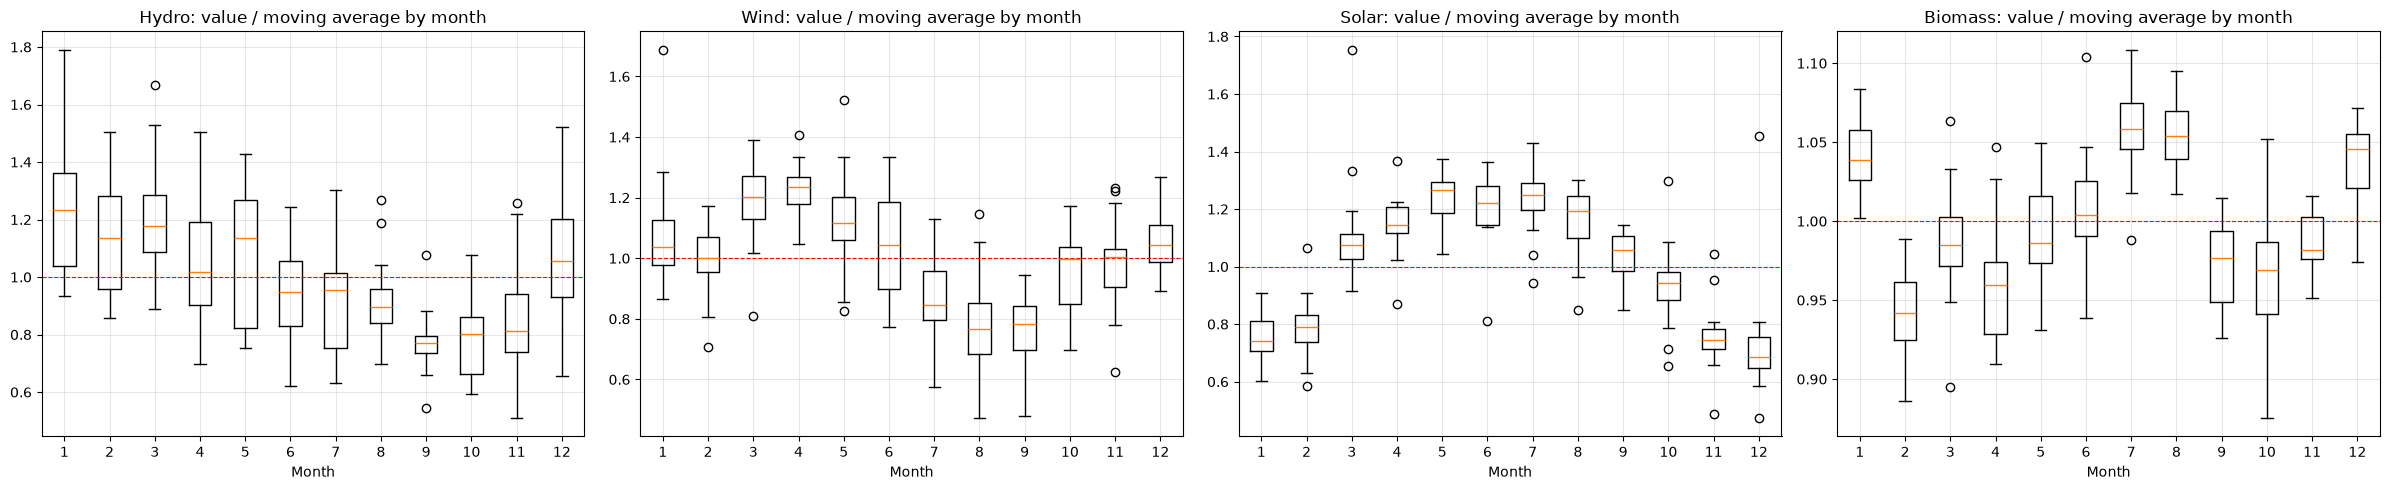

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, r in zip(axes, RESOURCES):
    s = series[r]
    ratio = (s / s.rolling(12, center=True).mean()).dropna()
    data = [ratio[ratio.index.month == m].values for m in range(1, 13)]
    ax.boxplot(data, tick_labels=range(1, 13))
    ax.axhline(1, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{r.capitalize()}: value / moving average by month")
    ax.set_xlabel("Month")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal decomposition (period = 12 months)
The decomposition type follows the variance check above: **multiplicative** if the rolling mean and rolling std are strongly correlated (> 0.7), otherwise **additive**.

Decomposition model chosen: {'hydro': 'additive', 'wind': 'multiplicative', 'solar': 'multiplicative', 'biomass': 'additive'}


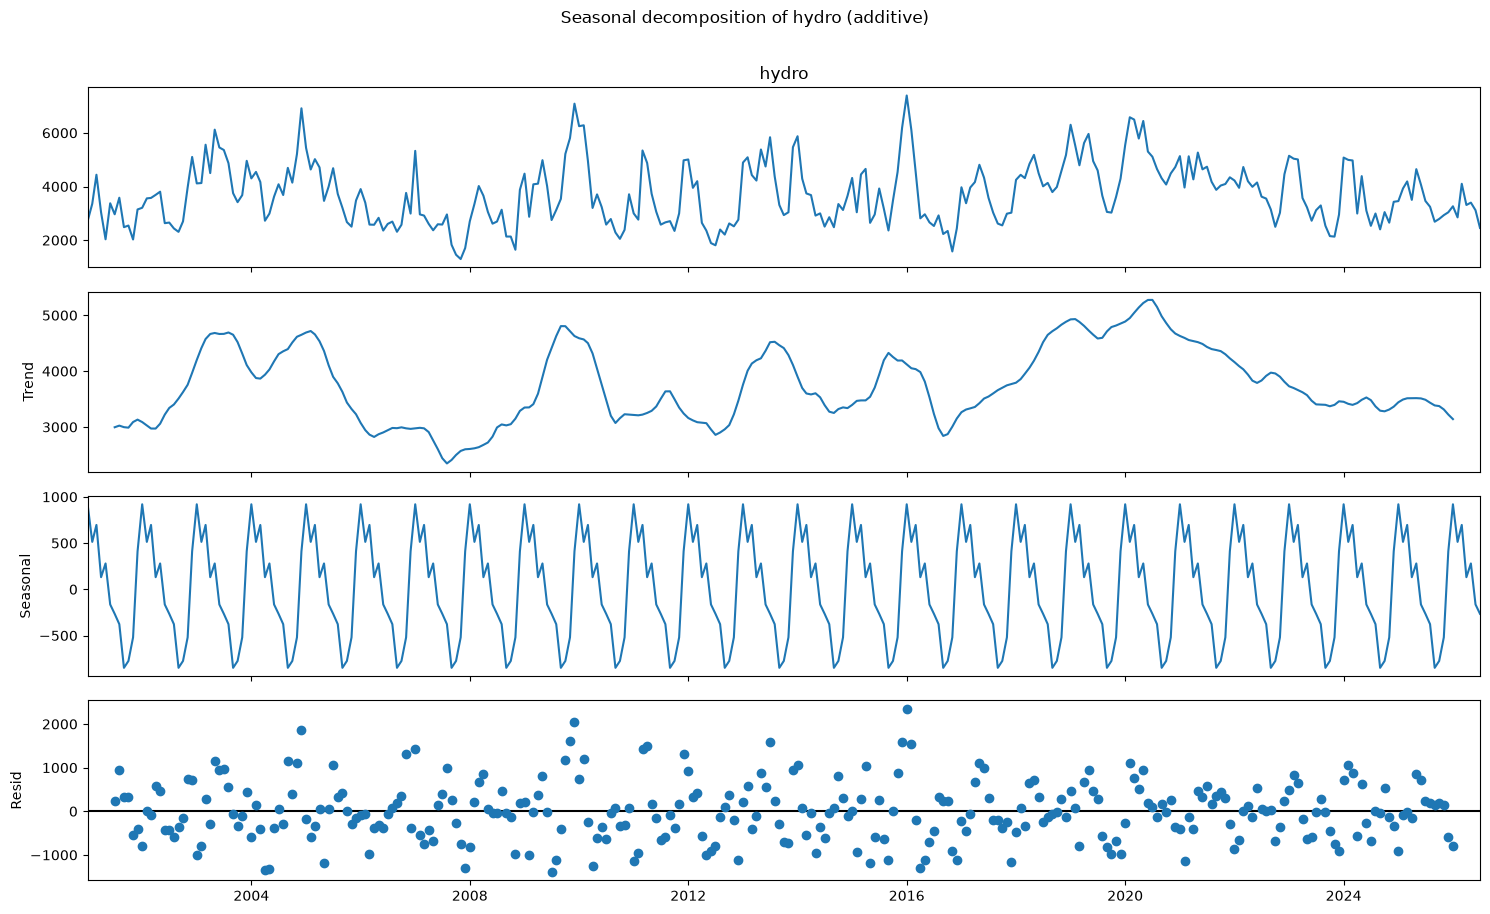

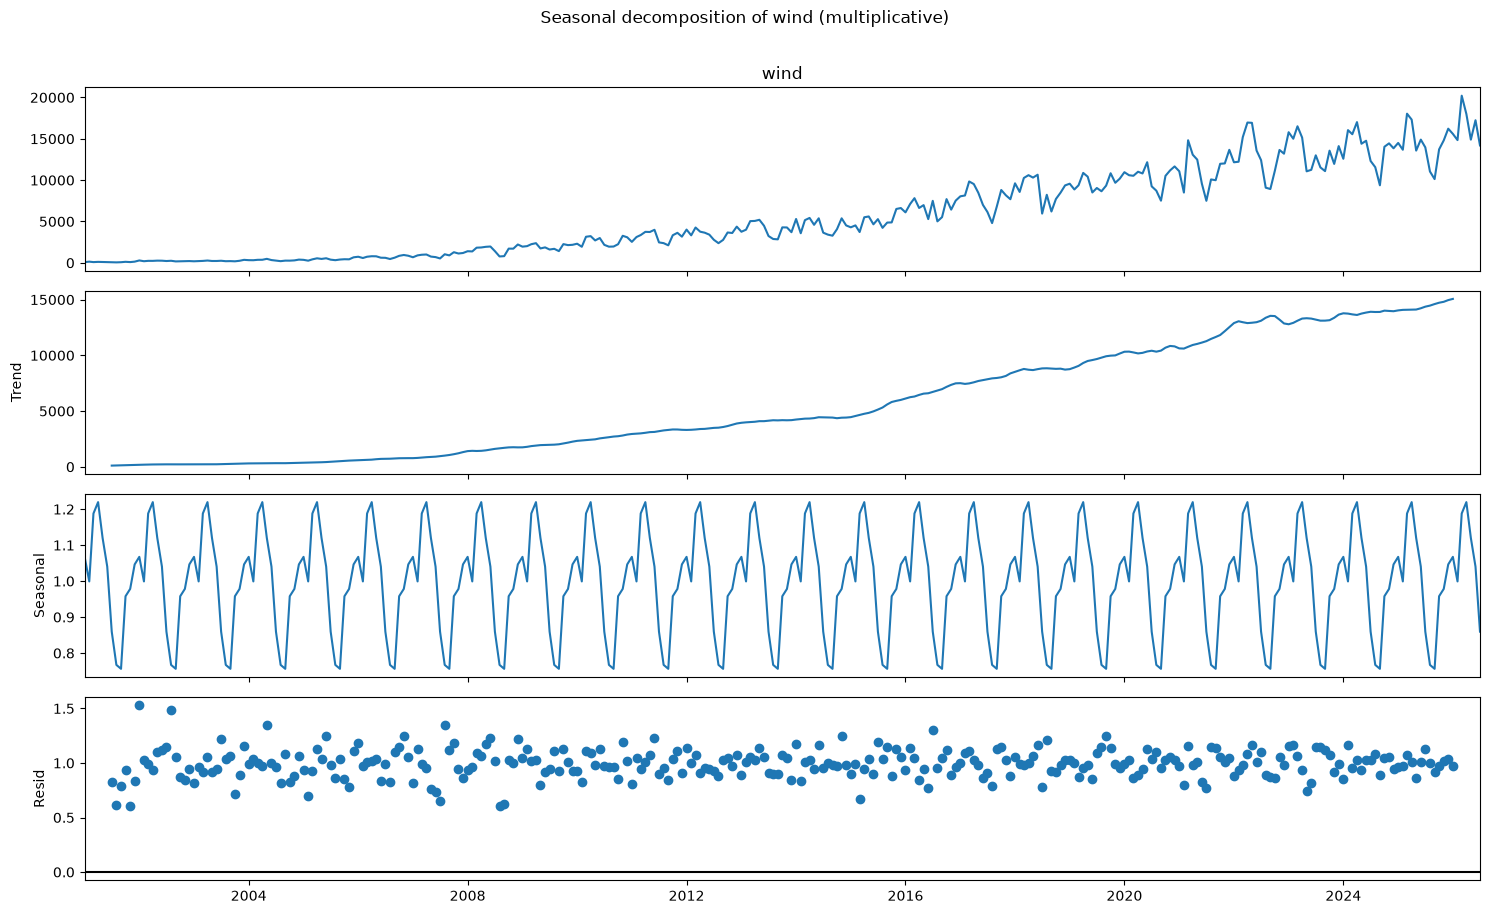

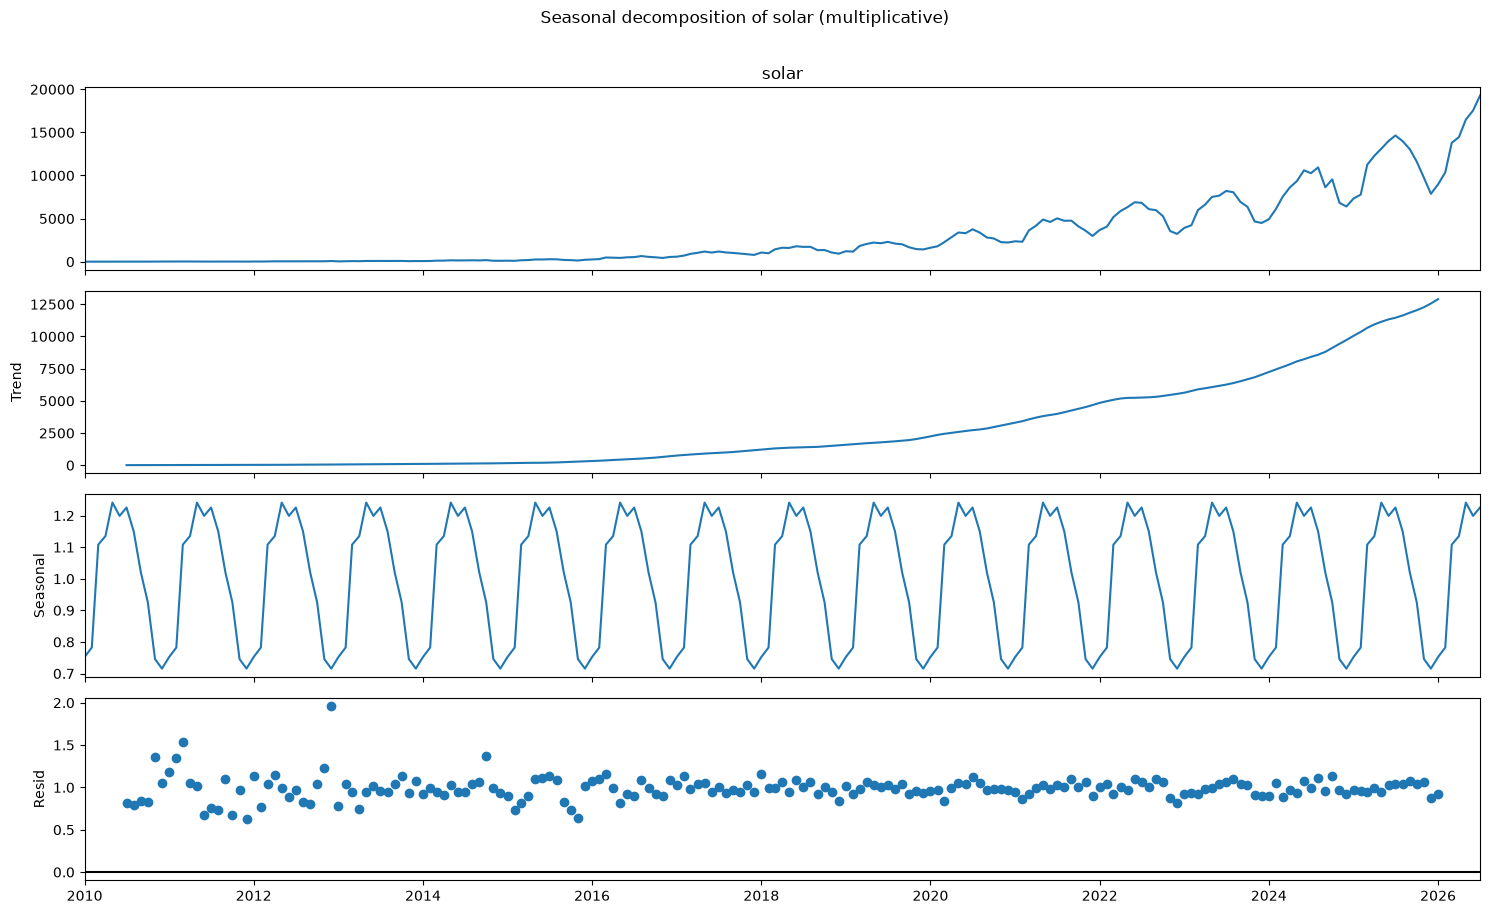

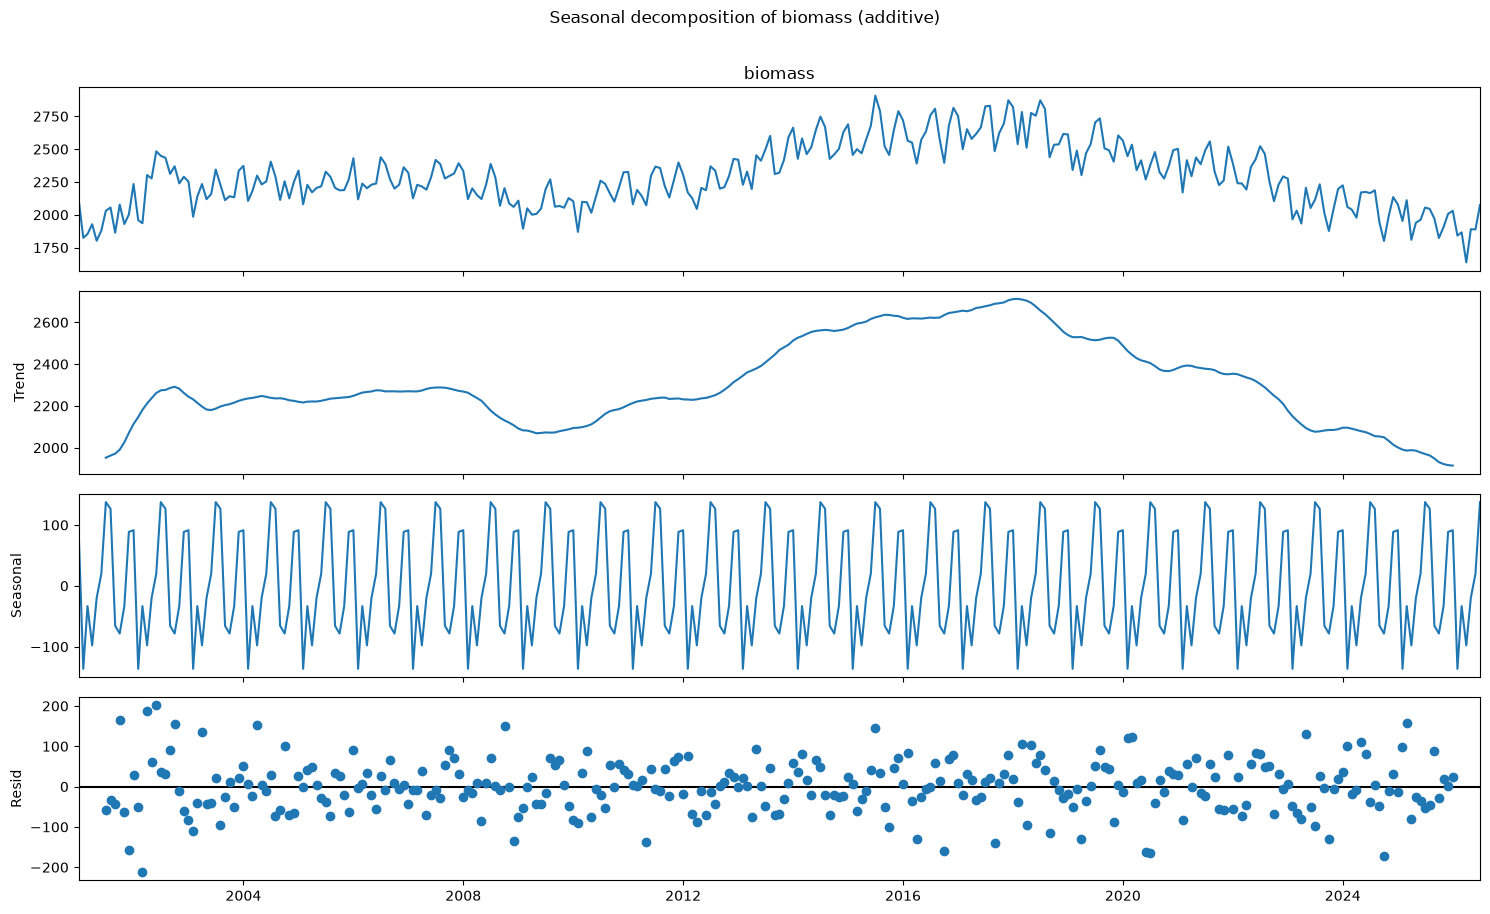

In [20]:
decomp_model = {}
for r in RESOURCES:
    corr = series[r].rolling(12).mean().corr(series[r].rolling(12).std())
    decomp_model[r] = "multiplicative" if corr > 0.7 else "additive"
print("Decomposition model chosen:", decomp_model)
decomposition = {}

for r in RESOURCES:
    decomposition[r] = seasonal_decompose(series[r], model=decomp_model[r], period=12)
    fig = decomposition[r].plot()
    fig.set_size_inches(15, 9)
    fig.suptitle(f"Seasonal decomposition of {r} ({decomp_model[r]})", y=1.01)
    plt.tight_layout()
    plt.show()

In [21]:
# Seasonal strength (0 = no seasonality, 1 = only seasonality) = 1 - Var(residual) / Var(seasonal + residual)
strength_rows = []
for r in RESOURCES:
    d = decomposition[r]
    if decomp_model[r] == "multiplicative":       # work on the log scale so the parts add up
        seas, resid, trend = np.log(d.seasonal), np.log(d.resid), np.log(d.trend)
    else:
        seas, resid, trend = d.seasonal, d.resid, d.trend
    seas, resid, trend = seas[resid.notna()], resid.dropna(), trend.dropna()
    strength_rows.append({
        "resource": r,
        "seasonal_strength": max(0, 1 - resid.var() / (seas + resid).var()),
        "trend_strength": max(0, 1 - resid.var() / (trend + resid).var()),
    })
strength = pd.DataFrame(strength_rows).set_index("resource")
strength

,seasonal_strength,trend_strength
resource,,
hydro,0.405,0.547
wind,0.547,0.991
solar,0.706,0.996
biomass,0.650,0.910


**Seasonal decomposition interpretation**

| Resource | Decomposition | Seasonal strength | Trend strength | Meaning |
|---|---|---|---|---|
| Hydro | additive | 0.41 | 0.55 | Real cycle, but a large irregular component (wet and dry years) |
| Wind | multiplicative | 0.55 | 0.99 | Dominated by the growth trend, with a moderate spring/summer cycle |
| Solar | multiplicative | 0.71 | 0.996 | Trend plus a clear summer cycle |
| Biomass | additive | 0.65 | 0.91 | Slow trend, with a small but very regular seasonal ripple |

All residual components are centred on zero. Their stationarity is tested in section 7.

### ACF of the original series
For monthly data, repeated peaks at lags 12, 24, 36 indicate a **yearly seasonal cycle**.

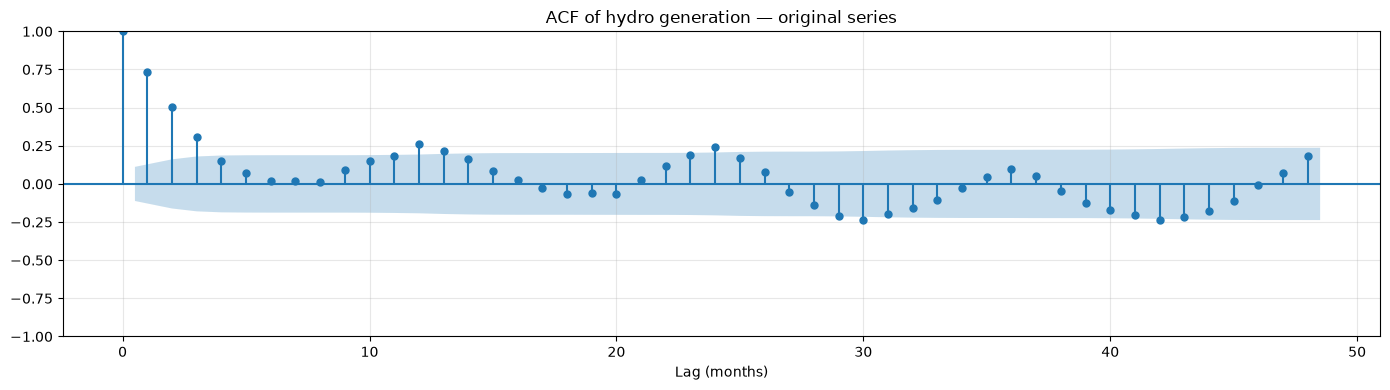

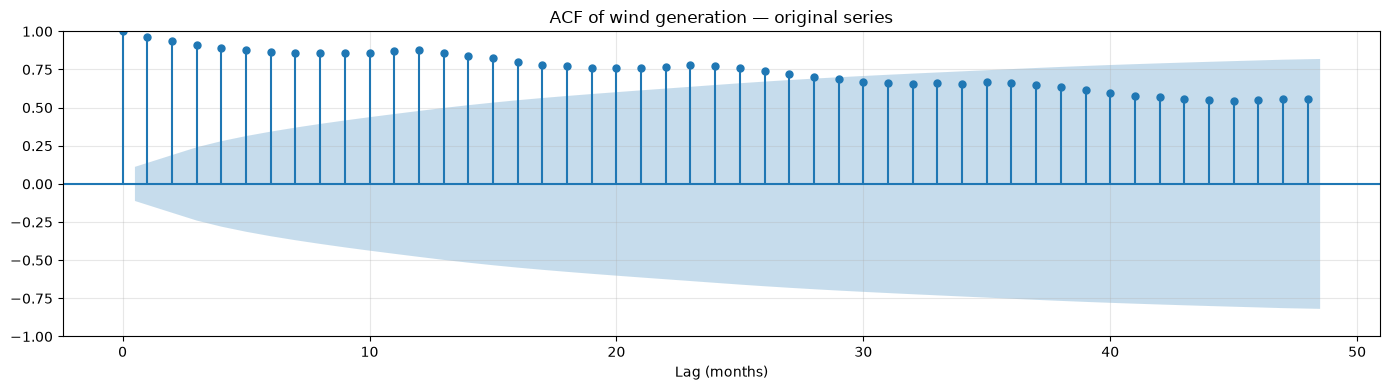

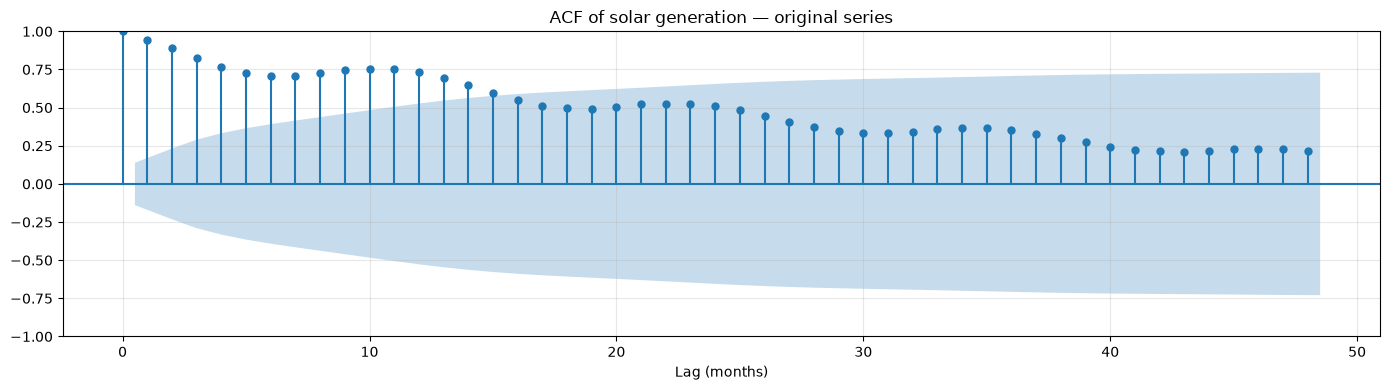

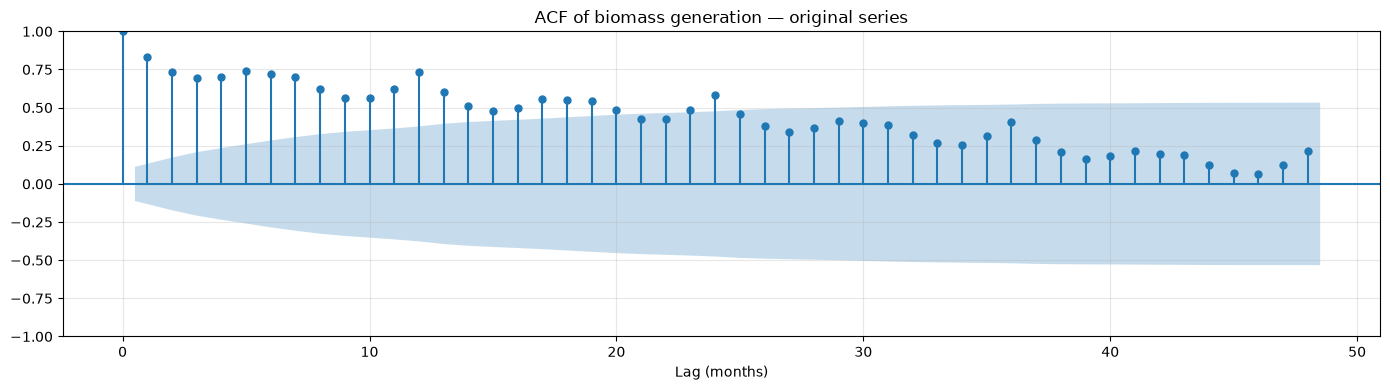

In [22]:
for r in RESOURCES:
    plt.figure(figsize=(14, 4))
    plot_acf(series[r], lags=48, ax=plt.gca())
    plt.title(f"ACF of {r} generation — original series")
    plt.xlabel("Lag (months)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

**ACF interpretation (original series)**

* **Hydro:** the ACF drops quickly (0.73 at lag 1, about 0 by lag 5), with smaller peaks near **lags 12 and 24** (about 0.25). This shows short memory plus a modest yearly cycle.
* **Wind:** the ACF is **very high and decays very slowly** (0.96 at lag 1, still 0.56 at lag 48), with bumps at 12, 24 and 36. This is typical of a strongly trending, non-stationary series with yearly seasonality.
* **Solar:** slow decay (above 0.5 for about 20 lags) with seasonal bumps near 12 and 24, so it is trending and non-stationary.
* **Biomass:** slow decay with clear peaks at **lags 12, 24 and 36**, showing a persistent trend plus a yearly cycle.

## 7. Stationarity Analysis

1. **ADF test**: H0 = the series has a unit root (non-stationary). p < 0.05 means stationary.
2. **KPSS test**: H0 = the series is stationary. p < 0.05 means non-stationary.

A series is called stationary only when **both** tests agree. The KPSS p-value is limited by its lookup table to the range 0.01–0.10.

In [23]:
alpha = 0.05

def stationarity_tests(x, name):
    x = x.dropna()
    adf_result = adfuller(x, regression="ct" if name.endswith("(original)") else "c")
    kpss_result = kpss(x, regression="ct" if name.endswith("(original)") else "c", nlags="auto")
    adf_ok = adf_result[1] < alpha
    kpss_ok = kpss_result[1] > alpha
    if adf_ok and kpss_ok:
        verdict = "Stationary"
    elif not adf_ok and not kpss_ok:
        verdict = "Non-stationary"
    else:
        verdict = "Mixed evidence"
    return {"series": name, "n": len(x), "ADF statistic": adf_result[0], "ADF p-value": adf_result[1],
            "KPSS statistic": kpss_result[0], "KPSS p-value": kpss_result[1], "Conclusion": verdict}

### 7.1 Original series (with constant + trend)

In [24]:
original_tests = pd.DataFrame([stationarity_tests(series[r], f"{r} (original)") for r in RESOURCES])
original_tests

,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,hydro (original),307,-3.247,0.075,0.103,0.100,Mixed evidence
1,wind (original),307,-2.098,0.547,0.697,0.010,Non-stationary
2,solar (original),199,1.497,1.000,0.522,0.010,Non-stationary
3,biomass (original),307,-1.152,0.920,0.455,0.010,Non-stationary


In [25]:
# Detailed output for one series, in the same format as the ADF / KPSS printouts
for r in RESOURCES:
    adf_result = adfuller(series[r].dropna(), regression="ct")
    print(f"ADF TEST - {r.upper()} (ORIGINAL SERIES)")
    print("-" * 50)
    print(f"ADF Statistic : {adf_result[0]:.6f}")
    print(f"p-value       : {adf_result[1]:.10f}")
    print(f"Lags Used     : {adf_result[2]}")
    print(f"Observations  : {adf_result[3]}")
    print("Critical Values:", {k: round(v, 3) for k, v in adf_result[4].items()})
    print()

ADF TEST - HYDRO (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -3.247399
p-value       : 0.0753638935
Lags Used     : 12
Observations  : 294
Critical Values: {'1%': np.float64(-3.99), '5%': np.float64(-3.426), '10%': np.float64(-3.136)}

ADF TEST - WIND (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -2.098029
p-value       : 0.5472000419
Lags Used     : 15
Observations  : 291
Critical Values: {'1%': np.float64(-3.99), '5%': np.float64(-3.426), '10%': np.float64(-3.136)}

ADF TEST - SOLAR (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : 1.497390
p-value       : 1.0000000000
Lags Used     : 15
Observations  : 183
Critical Values: {'1%': np.float64(-4.009), '5%': np.float64(-3.435), '10%': np.float64(-3.141)}

ADF TEST - BIOMASS (ORIGINAL SERIES)
--------------------------------------------------
ADF Statistic : -1.151926
p-value       : 0.9198983154
Lags Used     : 13
Observat

**Stationarity of the original series**

| Resource | ADF p | KPSS p | Conclusion |
|---|---|---|---|
| Hydro | 0.075 | 0.10 | Mixed. ADF narrowly fails to reject, while KPSS does not reject stationarity |
| Wind | 0.547 | 0.01 | **Non-stationary** |
| Solar | 1.000 | 0.01 | **Non-stationary** |
| Biomass | 0.920 | 0.01 | **Non-stationary** |

Wind, solar and biomass clearly need differencing. Hydro is examined further below.

### 7.2 Making the series stationary
We test the decomposition residual (trend and seasonality removed), the first difference (Δ), the seasonal difference (Δ12) and both together. Resources with multiplicative seasonality are log-transformed first.

In [26]:
# log makes growing seasonal swings constant (only for multiplicative resources)
transformed = {r: np.log(series[r]) if decomp_model[r] == "multiplicative" else series[r] for r in RESOURCES}
print("Log-transformed:", [r for r in RESOURCES if decomp_model[r] == "multiplicative"])

rows = []
for r in RESOURCES:
    z = transformed[r]
    resid = decomposition[r].resid
    if decomp_model[r] == "multiplicative":
        resid = np.log(resid)
    rows.append(stationarity_tests(z, f"{r}: level, constant only (no trend term)"))
    rows.append(stationarity_tests(resid, f"{r}: decomposition residual"))
    rows.append(stationarity_tests(z.diff(), f"{r}: first difference (d=1)"))
    rows.append(stationarity_tests(z.diff(12), f"{r}: seasonal difference (D=1)"))
    rows.append(stationarity_tests(z.diff(12).diff(), f"{r}: both (d=1, D=1)"))
transformed_tests = pd.DataFrame(rows)
transformed_tests

Log-transformed: ['wind', 'solar']


,series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Conclusion
0,"hydro: level, constant only (no trend term)",307,-3.312,0.014,0.240,0.100,Stationary
1,hydro: decomposition residual,295,-8.334,0.000,0.011,0.100,Stationary
2,hydro: first difference (d=1),306,-7.564,0.000,0.039,0.100,Stationary
3,hydro: seasonal difference (D=1),295,-4.737,0.000,0.063,0.100,Stationary
4,"hydro: both (d=1, D=1)",294,-8.812,0.000,0.026,0.100,Stationary
5,"wind: level, constant only (no trend term)",307,-3.993,0.001,2.711,0.010,Mixed evidence
6,wind: decomposition residual,295,-9.168,0.000,0.303,0.100,Stationary
7,wind: first difference (d=1),306,-6.621,0.000,0.423,0.067,Stationary
8,wind: seasonal difference (D=1),295,-2.665,0.080,1.482,0.010,Non-stationary
9,"wind: both (d=1, D=1)",294,-8.781,0.000,0.169,0.100,Stationary


**Stationarity analysis: final interpretation**

* **Hydro:** in levels with a constant only, ADF p = 0.014 and KPSS p ≥ 0.10, so hydro is **already stationary**. No differencing is needed (**d = 0, D = 0**). Seasonality is handled with seasonal AR/MA terms.
* **Wind (log scale):**
  * the level gives mixed evidence;
  * the seasonal difference alone is non-stationary (ADF p = 0.080, KPSS p = 0.01);
  * the **first difference** is stationary (ADF p < 0.001, KPSS p = 0.067).

  Wind's seasonal strength is 0.55 (below 0.64), so **d = 1, D = 0**.
* **Solar (log scale):** the seasonal difference alone is non-stationary (ADF p = 0.526). With both differences the series is stationary, so **d = 1, D = 1**.
* **Biomass:** the seasonal difference alone gives mixed evidence (KPSS p = 0.016). With both differences the series is stationary (ADF p < 0.001, KPSS p ≥ 0.10), so **d = 1, D = 1**.
* The decomposition residuals of all four resources are stationary by both tests.

## 8. ACF / PACF Analysis of the Stationary Series
The ACF and PACF are examined on the differenced series selected above. This is the series an ARIMA/SARIMA model works with.

hydro   : d=0, D=0 -> hydro (level)
wind    : d=1, D=0 -> Δ log(wind)
solar   : d=1, D=1 -> Δ Δ12 log(solar)
biomass : d=1, D=1 -> Δ Δ12 biomass


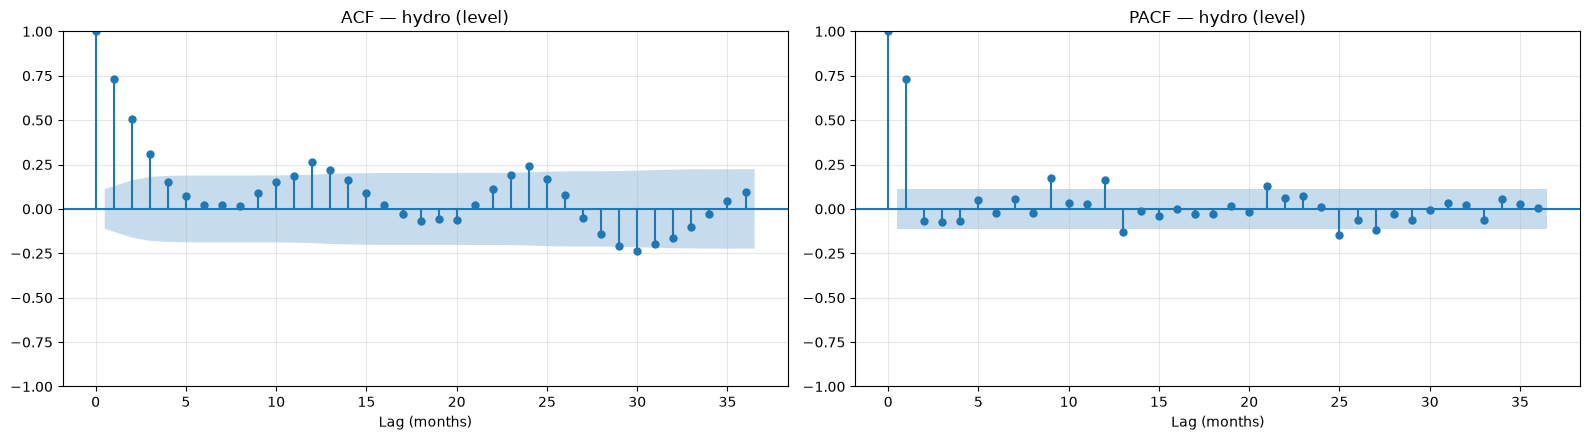

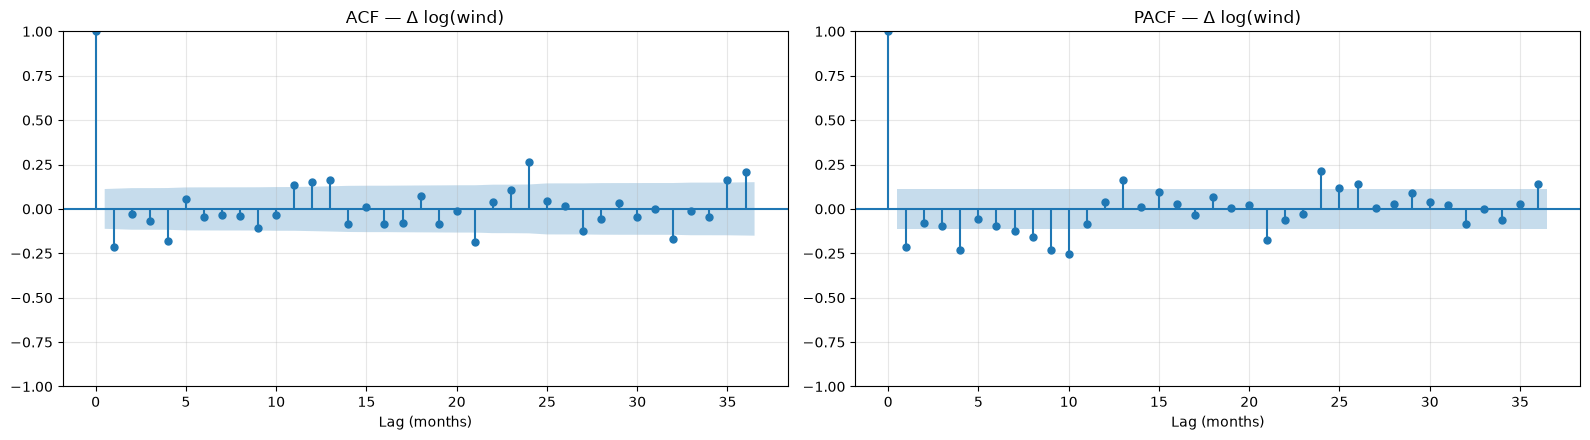

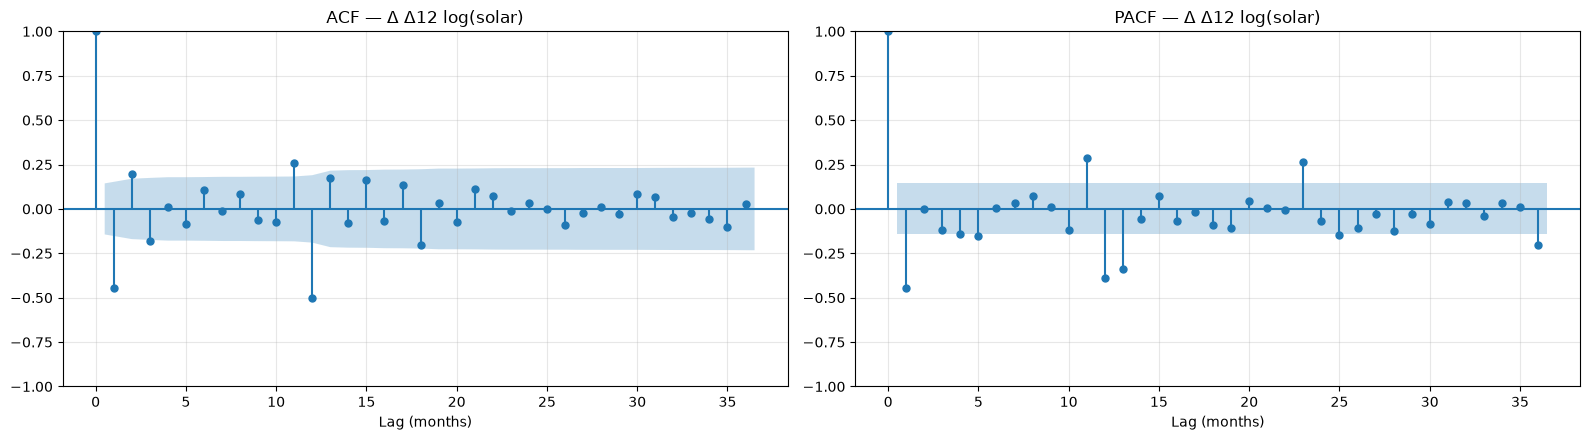

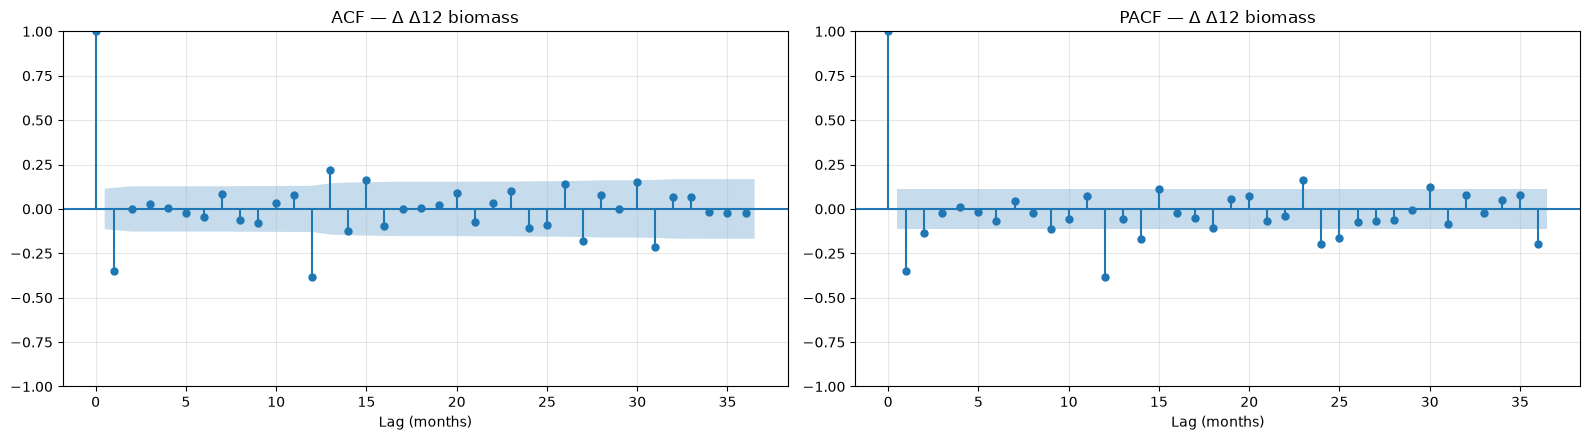

In [27]:
# Differencing rule (the same rule is applied automatically in Review 2):
#   D = 1 if the seasonal strength > 0.64 (strong seasonality -> seasonal difference)
#   d = 1 if the series (after D) is still not stationary by BOTH ADF (p<0.05) and KPSS (p>0.05)
def choose_differencing(z):
    parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = parts.resid.dropna(), parts.seasonal[parts.resid.notna()]
    D = 1 if max(0, 1 - resid.var() / (seas + resid).var()) > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    d = 0 if (adfuller(x)[1] < 0.05 and kpss(x, regression="c", nlags="auto")[1] > 0.05) else 1
    return d, D

stationary, stationary_label = {}, {}
for r in RESOURCES:
    d, D = choose_differencing(transformed[r])
    x = transformed[r]
    if D: x = x.diff(12)
    if d: x = x.diff()
    stationary[r] = x.dropna()
    name = f"log({r})" if decomp_model[r] == "multiplicative" else r
    stationary_label[r] = ("Δ " if d else "") + ("Δ12 " if D else "") + name + ("" if d or D else " (level)")
    print(f"{r:8s}: d={d}, D={D} -> {stationary_label[r]}")

for r in RESOURCES:
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    plot_acf(stationary[r], lags=36, ax=axes[0])
    plot_pacf(stationary[r], lags=36, method="ywm", ax=axes[1])
    axes[0].set_title(f"ACF — {stationary_label[r]}")
    axes[1].set_title(f"PACF — {stationary_label[r]}")
    for ax in axes:
        ax.set_xlabel("Lag (months)")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [28]:
from statsmodels.tsa.stattools import acf, pacf

acf_rows = []
for r in RESOURCES:
    x = stationary[r]
    bound = 1.96 / np.sqrt(len(x))
    a = acf(x, nlags=36)
    p = pacf(x, nlags=36, method="ywm")
    acf_rows.append({
        "resource": r,
        "series": stationary_label[r],
        "ACF lag 1": a[1], "ACF lag 12": a[12], "PACF lag 1": p[1], "PACF lag 12": p[12],
        "significant ACF lags (≤13)": [k for k in range(1, 14) if abs(a[k]) > bound],
        "significant PACF lags (≤13)": [k for k in range(1, 14) if abs(p[k]) > bound],
        "95% bound": bound,
    })
acf_summary = pd.DataFrame(acf_rows).set_index("resource")
acf_summary

,series,ACF lag 1,ACF lag 12,PACF lag 1,PACF lag 12,significant ACF lags (≤13),significant PACF lags (≤13),95% bound
resource,,,,,,,,
hydro,hydro (level),0.733,0.264,0.733,0.162,"[1, 2, 3, 4, 10, 11, 12, 13]","[1, 9, 12, 13]",0.112
wind,Δ log(wind),-0.214,0.149,-0.214,0.039,"[1, 4, 11, 12, 13]","[1, 4, 7, 8, 9, 10, 13]",0.112
solar,Δ Δ12 log(solar),-0.447,-0.501,-0.447,-0.390,"[1, 2, 3, 11, 12, 13]","[1, 5, 11, 12, 13]",0.144
biomass,Δ Δ12 biomass,-0.349,-0.384,-0.349,-0.383,"[1, 12, 13]","[1, 2, 12]",0.114


**ACF / PACF interpretation and suggested models**

| Resource | Pattern on the stationary series | Suggested model |
|---|---|---|
| Hydro (level) | The ACF decays gradually from 0.73, while the PACF has a single large spike at lag 1 (0.73) and small spikes at 12–13. This indicates an **AR(1)** plus a seasonal AR term | SARIMA(1,0,0)(1,0,1)12 with a constant |
| Wind (Δ log) | The ACF is −0.21 at lag 1 (the usual sign after first differencing), which suggests **MA(1)**. A significant ACF at **lag 12** (0.15) shows the yearly cycle remains, so seasonal AR/MA terms are needed | SARIMA(1,1,1)(1,0,1)12 |
| Solar (Δ Δ12 log) | ACF and PACF are −0.45 at lag 1, and the ACF is strongly negative at lag 12 (−0.50). This suggests AR(1) plus a **seasonal MA(1)** | SARIMA(1,1,0)(0,1,1)12 |
| Biomass (Δ Δ12) | The ACF is significant only at lags 1 (−0.35) and 12 (−0.38), the "airline" pattern | SARIMA(0,1,1)(0,1,1)12 |

In Review 2, the AIC search over all small models selects **exactly these four specifications**.

## 9. Initial Findings and Research Hypotheses

### Initial findings

1. **Hydro** (about 41,900 GWh in 2025) has **no long-term trend**. It is stationary, driven by wet and dry years, and peaks in winter (January +25%).
2. **Wind** is the South's **largest renewable** (171,871 GWh in 2025). It grew about 23%/yr, but growth has **slowed to about 3–4%/yr since 2023**. It peaks in spring (April +23%) and is lowest in September (−24%). It is modelled on the log scale with a first difference.
3. **Solar** has grown about 62%/yr (102 → 136,638 GWh, 2010–2025), with a strong multiplicative summer peak. It needs a log transform plus first and seasonal differencing.
4. **Biomass** peaked in 2017 and has declined since, with a small (±6%) but very regular seasonal cycle.
5. **Geothermal** generation is zero in every month in the South, so it cannot be modelled.
6. The seasonal cycles **complement each other**: hydro peaks in winter, wind in spring and solar in summer.
7. ACF/PACF give simple, distinct models for each resource:

   | Resource | Model |
   |---|---|
   | Hydro | AR(1) with seasonal ARMA terms |
   | Wind | (1,1,1)(1,0,1)12 |
   | Solar | (1,1,0)(0,1,1)12 |
   | Biomass | (0,1,1)(0,1,1)12 |

### Research hypotheses (tested in Review 2)

* **H1:** All four resources show significant 12-month seasonality, with different peak months: winter for hydro, spring for wind, summer for solar.
* **H2:** Seasonal models (SARIMA, Holt-Winters) forecast more accurately than the seasonal-naive baseline for each resource.
* **H3:** The growing resources (solar and wind) need models that capture growth. Trend-free models (naive, SES) will perform poorly for them.
* **H4:** Hydro is the hardest resource to forecast, because its variation is driven by unpredictable rainfall.